# Pretvaranje teksta u vektore

Računar ne razume reči, razume samo brojeve. Zato pre bilo kakve analize teksta (klasterovanje, klasifikacija, pretraga...) tekst moramo da pretvorimo u brojeve.

- **Tekst** je bilo koja rečenica ili priča, na primer „Maca pije mleko“.
- **Vektor** je spisak brojeva poređanih u red, na primer `[3, 0, 1, 5]`. Kao kada za svaku igračku zapišeš koliko je imaš: 3 autića, 0 lopti, 1 meda, 5 kocki. Svaki broj ima svoje stalno mesto.
- **Vektorizacija** (ili *embedding*) je pretvaranje teksta u vektor.

Želimo da tekstovi koji **znače nešto slično** dobiju **slične vektore**.

U ovoj svesci upoređujemo tri modela, od najjednostavnijeg do najpametnijeg:
1. **TF-IDF** - broji reči
2. **Word2Vec** - gleda s kim se reči druže
3. **Sentence-BERT** - čita celu rečenicu i razume značenje

In [ ]:

# !pip install scikit-learn gensim sentence-transformers

In [2]:
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Rečenice koje poredimo. Izabrane su tako da proverimo tri stvari:
- **pas / kuče** - različite reči, isto značenje
- **luk (povrće) / luk (oružje)** - ista reč, različito značenje
- **pljušti / pada kiša** - isto značenje, a nijedna zajednička reč

In [3]:
recenice = [
    "Pas laje u dvorištu.",
    "Kuče laje na poštara.",
    "Mačka pije mleko.",
    "Mama seče luk za supu.",
    "Strelac je napeo luk i odapeo strelu.",
    "Napolju pljušti.",
    "Pada jaka kiša.",
]

# kratki nazivi za tabele i grafike
oznake = ['pas', 'kuče', 'mačka', 'luk-povrće', 'luk-oružje', 'pljušti', 'kiša']

## Kako merimo da li su dva vektora slična? - Kosinusna sličnost

Neka je vektor **strelica** koja kreće iz iste tačke i pokazuje u nekom pravcu.
- sličnost je **1**  -> kada vektori imaju isti pravac i isti smer.
- sličnost je **0**  -> vektori su međusobno normalni.
- sličnost je **-1** -> kada vektori imaju isti pravac i razlicit smer(kod teksta se to retko dešava, uglavnom dobijamo brojeve od 0 do 1).

**Kosinusna sličnost** je broj koji kaže koliko dve strelice gledaju u istom pravcu (kosinus ugla između njih):

$$\cos(\theta) = \frac{A \cdot B}{\|A\| \, \|B\|}$$

Gleda se samo pravac, a ne dužina strelice. Zato duga i kratka rečenica o istoj temi i dalje mogu biti vrlo slične.

In [4]:
from sklearn.metrics.pairwise import cosine_similarity

def prikazi_slicnost(vektori, naslov):
    # racuna kosinusnu slicnost svake recenice sa svakom i crta toplotnu mapu
    slicnost = pd.DataFrame(cosine_similarity(vektori), index=oznake, columns=oznake)

    plt.figure(figsize=(8, 6))
    sns.heatmap(slicnost, annot=True, cmap='coolwarm', fmt='.2f', vmin=0, vmax=1, linewidths=0.5)
    plt.title(naslov)
    plt.show()
    return slicnost

## 1) TF-IDF 

- **Token** je jedan komadić teksta, najčešće jedna reč. **Tokenizacija** je seckanje teksta na tokene: „Pas laje.“ → `['pas', 'laje']`.
- **Rečnik** je spisak svih različitih reči iz svih priča. Svaka reč dobija svoju „fioku“, tj. svoje mesto u vektoru. Dužina vektora = broj reči u rečniku.
- **TF** (*term frequency*, učestalost reči) - koliko puta se reč pojavila **u ovoj priči**.
- **IDF** (*inverse document frequency*) - koliko je reč **retka** među svim pričama. Reči kao „i“, „je“, „u“ ima svuda, pa ne govore ništa posebno (kao kad kažeš „moj drug ima nos“ - svako ima nos!). One dobijaju mali IDF. Retka reč, kao „dinosaurus“, dobija veliki IDF.

$$\text{TF-IDF}(reč, priča) = TF \times IDF$$

Reč dobija veliki broj ako se **često javlja u ovoj priči**, a **retko u ostalim pričama**.

**Na osnovu čega pravi vektor:** samo na osnovu **brojanja reči**. Ne zna šta reči znače i ne gleda redosled reči.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer() # sam radi tokenizaciju i pretvara sva slova u mala
X_tfidf = tfidf.fit_transform(recenice) # fit -> pravi recnik i racuna IDF, transform -> pravi vektore

print('Recnik:', tfidf.get_feature_names_out())
print('Dimenzije:', X_tfidf.shape) # (broj recenica, broj reci u recniku)

Recnik: ['dvorištu' 'jaka' 'je' 'kiša' 'kuče' 'laje' 'luk' 'mama' 'mačka' 'mleko'
 'na' 'napeo' 'napolju' 'odapeo' 'pada' 'pas' 'pije' 'pljušti' 'poštara'
 'seče' 'strelac' 'strelu' 'supu' 'za']
Dimenzije: (7, 24)


In [6]:
# X_tfidf je retka matrica (sparse) - cuva samo brojeve razlicite od nule, jer je vecina nula
# toarray() je pretvara u obicnu matricu da bismo je videli
df_tfidf = pd.DataFrame(X_tfidf.toarray(), index=oznake, columns=tfidf.get_feature_names_out())
df_tfidf.round(2)

,dvorištu,jaka,je,kiša,kuče,laje,luk,mama,mačka,mleko,...,pada,pas,pije,pljušti,poštara,seče,strelac,strelu,supu,za
pas,0.61,0.00,0.00,0.00,0.00,0.51,0.00,0.00,0.00,0.00,...,0.00,0.61,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
kuče,0.00,0.00,0.00,0.00,0.52,0.43,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.52,0.00,0.00,0.00,0.00,0.00
mačka,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.58,0.58,...,0.00,0.00,0.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00
luk-povrće,0.00,0.00,0.00,0.00,0.00,0.00,0.38,0.46,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.46,0.00,0.00,0.46,0.46
luk-oružje,0.00,0.00,0.42,0.00,0.00,0.00,0.35,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.42,0.42,0.00,0.00
pljušti,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.71,0.00,0.00,0.00,0.00,0.00,0.00
kiša,0.00,0.58,0.00,0.58,0.00,0.00,0.00,0.00,0.00,0.00,...,0.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


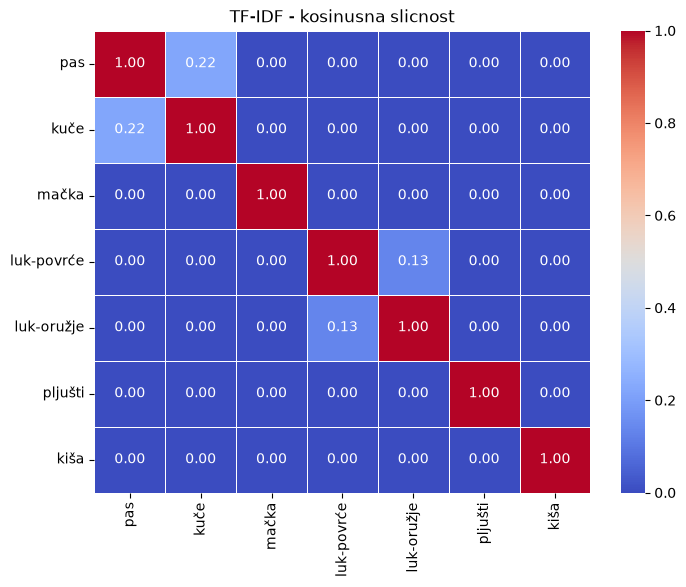

In [7]:
slicnost_tfidf = prikazi_slicnost(X_tfidf, 'TF-IDF - kosinusna slicnost')

**Zaključak**
- **pas / kuče** su slični samo zato što obe rečenice imaju reč „laje“. Za TF-IDF su „pas“ i „kuče“ dve potpuno različite fioke.
- **luk-povrće / luk-oružje** imaju sličnost veću od nule samo zbog iste reči „luk“, iako govore o potpuno različitim stvarima.
- **pljušti / kiša** imaju sličnost **0**, jer nemaju nijednu zajedničku reč, iako znače isto.

Prednosti: brz, jednostavan, lako se objašnjava. Za mnoge zadatke (npr. klasifikacija dužih tekstova) i dalje radi sasvim dobro.

### Normalizacija reči: stemovanje i lematizacija

Za TF-IDF su „pas“ i „psi“, kao i „laje“ i „laju“, **potpuno različite reči** (različite fioke). Zato „Pas laje u dvorištu“ i „Psi laju na poštara“ imaju sličnost 0. Pre vektorizacije reči možemo da svedemo na zajednički oblik:

- **Stemovanje** (*stemming*) - po spisku pravila **odseca nastavak** i ostavlja **koren** („laje“, „laju“ → `laj`). Brzo je, ali grubo: koren ne mora da bude prava reč, a nepravilne oblike („pas“ / „psi“) ne prepoznaje.
- **Lematizacija** - reč vraća u **osnovni oblik iz rečnika** (**lema**): „psi“ → `pas`, „laju“ → `lajati`. Pre toga odredi **vrstu reči** (imenica, glagol...). Tačnija je, ali sporija i treba joj model za taj jezik.

Ispod je primer za engleski (biblioteka **NLTK**), a u komentarima su biblioteke za srpski.

In [8]:
# !pip install nltk
from nltk.stem import PorterStemmer, SnowballStemmer

porter = PorterStemmer()
snowball = SnowballStemmer('english')

reci_en = ['running', 'runs', 'studies', 'studying', 'dogs']
print('Porter:  ', [porter.stem(r) for r in reci_en])
print('Snowball:', [snowball.stem(r) for r in reci_en])

# Srpski - stemovanje: Snowball stemer za srpski
# !pip install snowballstemmer
# import snowballstemmer
# stemer_sr = snowballstemmer.stemmer('serbian')
# stemer_sr.stemWords(['kuća', 'kućama', 'laje', 'laju'])

Porter:   ['run', 'run', 'studi', 'studi', 'dog']
Snowball: ['run', 'run', 'studi', 'studi', 'dog']


In [9]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet=True) # recnik engleskog jezika (WordNet), preuzima se jednom

lematizator = WordNetLemmatizer()
print([lematizator.lemmatize(r) for r in ['dogs', 'studies', 'data']])                 # podrazumevano pos='n' (imenica)
print([lematizator.lemmatize(r, pos='v') for r in ['running', 'linked', 'studies']])  # pos='v' -> glagol

# spaCy - sam odredi vrstu reci iz recenice, pa nadje lemu
# !pip install spacy && python -m spacy download en_core_web_sm
# import spacy
# nlp = spacy.load('en_core_web_sm')
# [t.lemma_ for t in nlp('The dogs were running in the park')]

# Srpski - lematizacija: classla (odredi vrstu reci + lemu)
# !pip install classla
# import classla
# classla.download('sr')
# nlp = classla.Pipeline('sr', processors='tokenize,pos,lemma')
# doc = nlp('Psi laju na poštara.')
# [rec.lemma for recenica in doc.sentences for rec in recenica.words]

['dog', 'study', 'data']
['run', 'link', 'study']


### Grupe slova umesto reči (char n-grami)

**N-gram** je grupa od **n slova koja stoje jedno do drugog**. Umesto da tekst seče na reči, model svaku reč iseče na takve komadiće, i svaki komadić dobije svoju fioku.

- `analyzer='char_wb'` - komadići slova, ali **unutar reči** (*wb* = *word boundary*, granica reči). Oko svake reči doda razmak, da se zna gde reč počinje i završava.
- `ngram_range=(2, 4)` - uzima **sve** komadiće od 2, od 3 i od 4 slova.

„laje“ → `' l'`, `'la'`, `'aj'`, `'je'`, `'e '`, `' la'`, `'laj'`, `'aje'`, `'je '`, `' laj'`, `'laje'`, `'aje '`

Isti komadić iz različitih reči ide u **istu fioku** (`'laj'` iz „laje“ i iz „laju“), pa slični oblici reči postaju slični. Pomaže i kod grešaka u kucanju i pisanja bez kvačica. Ne treba nikakvo znanje jezika, ali je rečnik mnogo veći.

In [10]:
tfidf_char = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)) # komadici od 2, 3 i 4 slova, unutar reci
X_char = tfidf_char.fit_transform(recenice)

print('Dimenzije:', X_char.shape) # za reci je bilo (7, 24)
print('Prvih 20 komadica u recniku:', tfidf_char.get_feature_names_out()[:20])

df_char = pd.DataFrame(X_char.toarray(), index=oznake, columns=tfidf_char.get_feature_names_out())
df_char.round(2)

Dimenzije: (7, 274)
Prvih 20 komadica u recniku: [' d' ' dv' ' dvo' ' i' ' i ' ' j' ' ja' ' jak' ' je' ' je ' ' k' ' ki'
 ' kiš' ' ku' ' kuč' ' l' ' la' ' laj' ' lu' ' luk']


,d,dv,dvo,i,i,j,ja,jak,je,je,...,ša,ša.,ša.,št,šta,štar,šti,šti.,štu,štu.
pas,0.16,0.16,0.16,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.11,0.00,0.00,0.00,0.00,0.16,0.16
kuče,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.11,0.15,0.15,0.00,0.00,0.00,0.00
mačka,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
luk-povrće,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
luk-oružje,0.00,0.00,0.00,0.09,0.09,0.07,0.00,0.00,0.09,0.09,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
pljušti,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.10,0.00,0.00,0.15,0.15,0.00,0.00
kiša,0.00,0.00,0.00,0.00,0.00,0.14,0.17,0.17,0.00,0.00,...,0.17,0.17,0.17,0.00,0.00,0.00,0.00,0.00,0.00,0.00


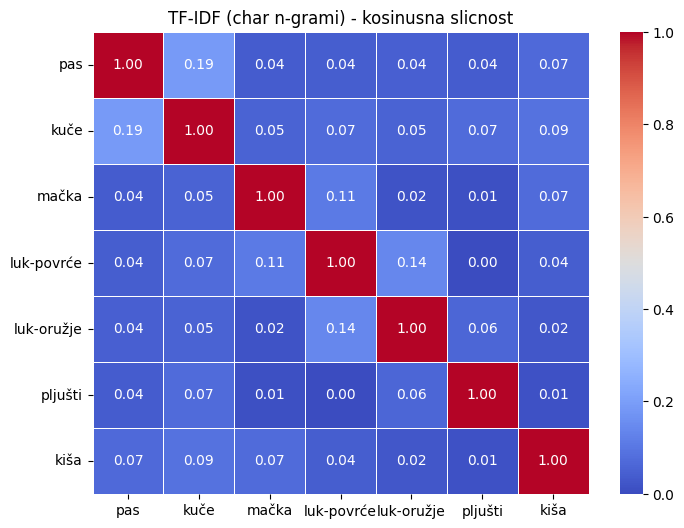

In [11]:
slicnost_char = prikazi_slicnost(X_char, 'TF-IDF (char n-grami) - kosinusna slicnost')

**Šta vidimo:**
- Rečnik ima **274** komadića umesto 24 reči. Vektori su duži i u svakom redu ima više brojeva različitih od nule.
- Interpunkcija ostaje deo komadića (`'ša.'`, `'šti.'`), a ostaju i reči od jednog slova (`' i '`), koje su se kod običnog TF-IDF-a gubile.
- **pas / kuče** su i dalje slični samo zbog „laje“, a **pljušti / kiša** su i dalje skoro 0. Komadići slova ne razumeju značenje, samo hvataju slične oblike reči.
- Skoro svi parovi imaju malu sličnost veću od nule, jer kratki komadići postoje u mnogo nepovezanih reči (npr. `'ma'` u „mama“ i „mačka“). To je **lažna sličnost**.

## 2) Word2Vec

- **Kontekst** su reči koje stoje oko neke reči. U rečenici „Maca pije mleko“ kontekst reči „pije“ su „maca“ i „mleko“.
- **Prozor** (*window*) određuje koliko reči levo i desno gledamo kao kontekst.
- **Neuronska mreža** je program koji uči kao dete: pokuša, pogreši, malo se popravi, pa opet pokuša.
- **Treniranje** je to ponavljano učenje na mnogo primera. Jedan prolazak kroz sve primere zove se **epoha**.

Word2Vec igra igru pogađanja. U varijanti **Skip-gram** dobije jednu reč i pogađa koje reči stoje oko nje: „Ako vidim *pije*, da li su pored nje *maca* i *mleko*?“ Svaki put kada pogreši, malo popravi brojeve u vektoru te reči.

Posle treniranja svaka reč ima svoj vektor (npr. 20, 100 ili 300 brojeva). Reči koje se pojavljuju u **sličnom društvu** dobiju **slične vektore**.

**Na osnovu čega pravi vektor:** na osnovu **konteksta** - reči koje okružuju datu reč.

### Korpus za treniranje

**Korpus** je velika gomila teksta na kojoj model uči. Pravi Word2Vec modeli uče na milionima rečenica (npr. cela Vikipedija).

Za potrebe ovog primera napravljen je mali **veštački korpus** iz šablona, tako da model uči brzo i da se jasno vidi ideja: reči „pas“ i „kuče“ se pojavljuju u istim šablonima (isto društvo), a reč „luk“ i u kuhinji i u bitki.

In [8]:
import random

# svaki sablon ima tri dela; recenica se pravi tako sto se iz svakog dela nasumicno izabere po jedan izraz
sabloni = {
    'psi':    [['pas', 'kuče'], ['laje', 'reži', 'maše repom', 'glođe kost', 'čuva kuću'], ['u dvorištu', 'na poštara', 'ispred kuće', 'na livadi']],
    'mačke':  [['mačka', 'mače'], ['pije mleko', 'prede', 'mjauče', 'lovi miša', 'spava'], ['na prozoru', 'u fotelji', 'pored peći', 'na tavanu']],
    'povrće': [['kupio sam', 'mama seče', 'baka ljušti', 'kuvar dinsta'], ['luk', 'krompir', 'šargarepu', 'papriku'], ['na pijaci', 'za supu', 'u kuhinji', 'za ručak']],
    'oružje': [['strelac je napeo', 'vitez nosi', 'lovac drži', 'ratnik je odapeo'], ['luk', 'strelu', 'mač', 'štit'], ['u bitki', 'u šumi', 'na turniru', 'pred zamkom']],
    'vreme':  [['napolju', 'danas', 'opet', 'ceo dan'], ['pljušti', 'pada jaka kiša', 'lije kiša', 'grmi', 'duva vetar'], ['i sve je mokro', 'pa nosimo kišobran', 'i nebo je tmurno', 'pa ostajemo kod kuće']],
}

random.seed(42)
korpus = []
for tema, delovi in sabloni.items():
    for _ in range(300): # 300 recenica po temi
        korpus.append(' '.join(random.choice(deo) for deo in delovi))

print(len(korpus))
korpus[:3] + korpus[600:603] + korpus[900:903]

1500


['pas laje ispred kuće',
 'pas reži na poštara',
 'pas čuva kuću u dvorištu',
 'kupio sam papriku za ručak',
 'baka ljušti luk za supu',
 'kupio sam papriku u kuhinji',
 'strelac je napeo strelu u bitki',
 'ratnik je odapeo mač pred zamkom',
 'lovac drži strelu u šumi']

In [9]:
def tokenizuj(tekst):
    # mala slova + izdvajanje reci (\w+ hvata i slova sa kvacicama)
    return re.findall(r'\w+', tekst.lower())

korpus_tokeni = [tokenizuj(r) for r in korpus]
korpus_tokeni[:3]

[['pas', 'laje', 'ispred', 'kuće'],
 ['pas', 'reži', 'na', 'poštara'],
 ['pas', 'čuva', 'kuću', 'u', 'dvorištu']]

In [10]:
from gensim.models import Word2Vec

w2v = Word2Vec(
    korpus_tokeni,
    vector_size=20, # duzina vektora za svaku rec
    window=3,       # prozor - koliko reci levo i desno se gleda kao kontekst
    min_count=1,    # rec mora da se pojavi bar 1 put da bi usla u recnik
    sg=1,           # 1 = Skip-gram (iz reci pogadja kontekst), 0 = CBOW (iz konteksta pogadja rec)
    epochs=20,      # broj prolazaka kroz korpus
    seed=42,
    workers=1,      # jedna nit - da bi rezultat bio ponovljiv
)

print('Broj reci u recniku:', len(w2v.wv))
print('Vektor za rec "pas":')
print(w2v.wv['pas'].round(2))

Broj reci u recniku: 88
Vektor za rec "pas":
[-0.07 -0.43  0.63 -0.26 -0.16  1.15 -0.58 -0.39 -0.15 -1.6   0.57 -0.33
  0.31  0.62 -0.23 -0.78  0.61  0.45  0.02  0.13]


Pogledajmo koje reči model smatra najsličnijim (najbližim po kosinusnoj sličnosti):

In [11]:
for rec in ['pas', 'pljušti', 'luk']:
    print(rec, '->', [(r, round(s, 2)) for r, s in w2v.wv.most_similar(rec, topn=5)])

pas -> [('kuče', 1.0), ('livadi', 0.99), ('poštara', 0.99), ('dvorištu', 0.99), ('kost', 0.98)]
pljušti -> [('grmi', 1.0), ('lije', 0.99), ('kiša', 0.98), ('danas', 0.98), ('napolju', 0.98)]
luk -> [('kuhinji', 0.82), ('lovac', 0.82), ('bitki', 0.81), ('sam', 0.8), ('drži', 0.8)]


- **pas** → **kuče** je na vrhu, iako to nigde nismo rekli. Model je to sam zaključio iz društva u kome se reči pojavljuju.
- **pljušti** → blizu su reči o kiši i lošem vremenu.
- **luk** → mešaju se reči iz kuhinje i iz bitke. Svaka reč ima **samo jedan vektor**, pa je vektor reči „luk“ mešavina oba značenja.

### Od vektora reči do vektora rečenice

Word2Vec daje vektor za svaku **reč**. Najjednostavniji način da dobijemo vektor **rečenice** je da izračunamo **prosek** vektora njenih reči.

Pri tome izbacujemo **stop reči** - kratke reči koje se javljaju svuda („i“, „u“, „na“, „je“...) i ne nose značenje. Ista ideja kao IDF kod TF-IDF-a.

In [12]:
stop_reci = {'i', 'u', 'na', 'je', 'sam', 'pa', 'za', 'pred', 'sve', 'kod'}

def vektor_recenice(recenica):
    # prosek vektora reci koje model zna i koje nisu stop reci
    reci = [r for r in tokenizuj(recenica) if r in w2v.wv and r not in stop_reci]
    return np.mean([w2v.wv[r] for r in reci], axis=0)

X_w2v = np.array([vektor_recenice(r) for r in recenice])
print(X_w2v.shape)

(7, 20)


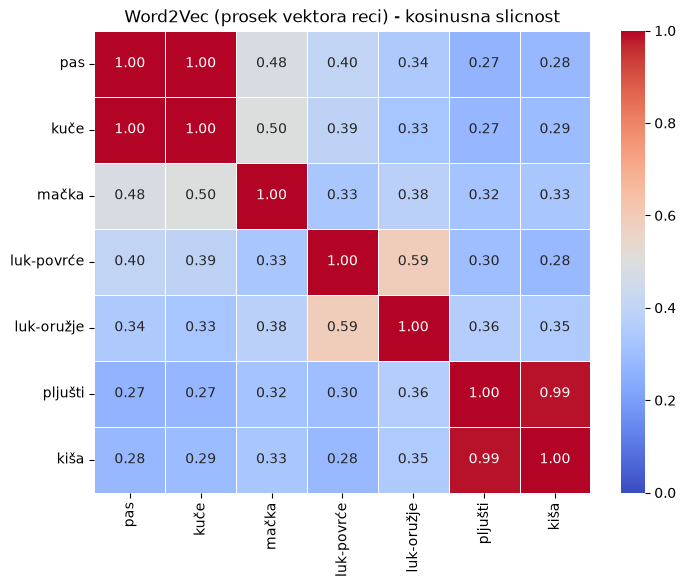

In [13]:
slicnost_w2v = prikazi_slicnost(X_w2v, 'Word2Vec (prosek vektora reci) - kosinusna slicnost')

**Šta vidimo:**
- **pas / kuče** i **pljušti / kiša** su sada skoro isti - model zna da te reči znače slično. TF-IDF to nije mogao.
- **luk-povrće / luk-oružje** su i dalje primetno slični, jer reč „luk“ uvek ima isti vektor, bez obzira na rečenicu.
- Prosek ne vodi računa o redosledu reči: „pas ujeda čoveka“ i „čovek ujeda psa“ dobijaju skoro isti vektor.

## 3) Sentence-BERT 

- **Transformer** je posebna, velika neuronska mreža koja gleda **sve reči u rečenici odjednom**.
- **Pažnja** (*attention*) je način na koji transformer za svaku reč pita: „Na koje druge reči ovde treba da obratim pažnju?“ Kod reči „luk“ primeti reč „supu“ ili „strelac“ i po tome odluči šta „luk“ znači.
- **BERT** je transformer koji je učio igrajući **igru skrivenih reči**: sakrije se jedna reč („Maca pije ___“), a on pogađa koja je („mleko“). Tu igru je igrao na milionima rečenica.
- **Prethodno istreniran model** (*pretrained*) - neko je već odradio to dugo i skupo učenje, a mi ga samo preuzmemo i koristimo.
- **Sentence-BERT** je BERT koji je **dodatno učen** na parovima rečenica koje znače isto, tako da **cela rečenica** dobije jedan vektor. Rečenice istog značenja dobiju bliske vektore, čak i bez zajedničkih reči.

**Na osnovu čega pravi vektor:** na osnovu **značenja cele rečenice** - svaka reč se tumači u zavisnosti od reči oko nje.

Koristimo model `paraphrase-multilingual-mpnet-base-v2` koji razume i srpski. Prvi put se preuzima sa interneta (oko 1 GB). Postoji i manji `paraphrase-multilingual-MiniLM-L12-v2`, ali on znatno lošije razume srpski.

In [14]:
from sentence_transformers import SentenceTransformer

sbert = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')

X_sbert = sbert.encode(recenice)
print(X_sbert.shape) # svaka recenica -> vektor od 768 brojeva

(7, 768)


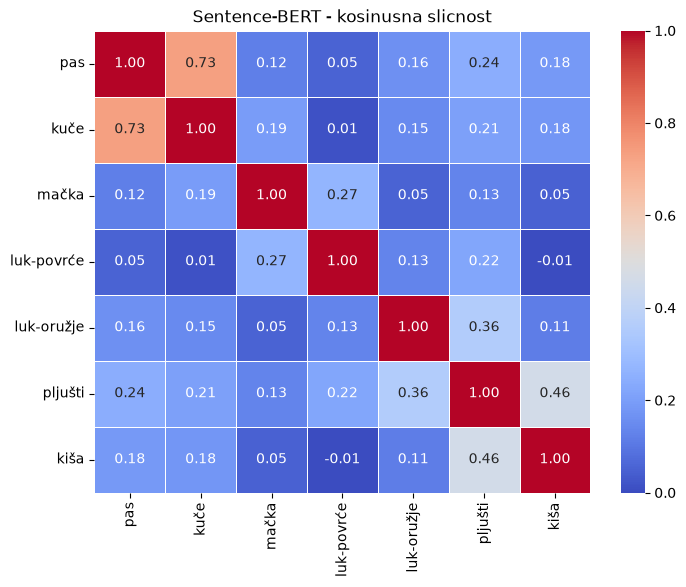

In [15]:
slicnost_sbert = prikazi_slicnost(X_sbert, 'Sentence-BERT - kosinusna slicnost')

**Šta vidimo:**
- **pas / kuče** i **pljušti / kiša** su najsličniji parovi u svojim redovima, iako je model učen na pravom jeziku, a ne na našim šablonima.
- **luk-povrće / luk-oružje** više nisu posebno slični - model razume da je u pitanju druga stvar.
- Brojevi su generalno manji nego kod Word2Vec-a jer je ovaj prostor mnogo veći (768 dimenzija) i model razlikuje mnogo više značenja.

### Isti „luk“, različiti vektori

Transformer pravi vektor i za svaki **token** posebno, u zavisnosti od rečenice. Uporedimo vektore reči „luk“ iz četiri različite rečenice.

Model ne seče tekst baš na cele reči nego na **podreči** (*subword*): „Strelac“ → `['▁Stre', 'lac']`. Znak `▁` označava početak reči. Reč „luk“ je dovoljno česta pa ostaje ceo token `▁luk`.

['▁Stre', 'lac', '▁je', '▁na', 'pe', 'o', '▁luk', '.']


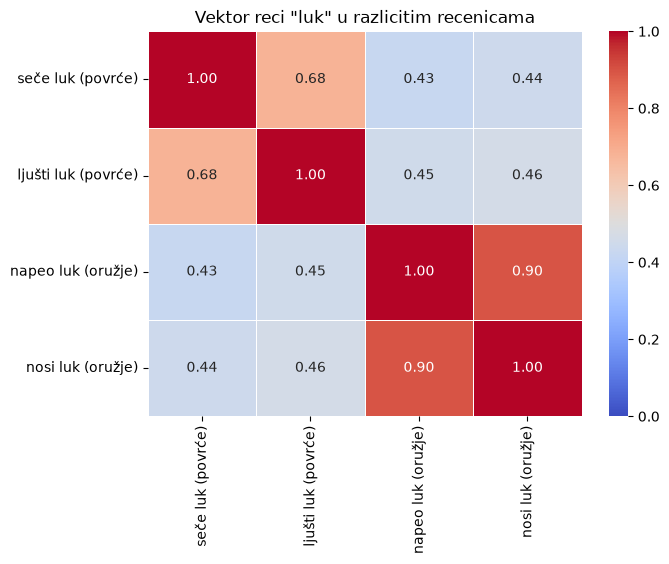

In [16]:
luk_recenice = [
    "Mama seče luk za supu.",
    "Baka ljušti luk i krompir.",
    "Strelac je napeo luk.",
    "Vitez nosi luk i strelu.",
]
luk_oznake = ['seče luk (povrće)', 'ljušti luk (povrće)', 'napeo luk (oružje)', 'nosi luk (oružje)']

print(sbert.tokenizer.tokenize(luk_recenice[2]))

# output_value='token_embeddings' -> vektor za svaki token umesto jednog vektora za celu recenicu
tokeni_vektori = sbert.encode(luk_recenice, output_value='token_embeddings')

luk_vektori = []
for recenica, vektori in zip(luk_recenice, tokeni_vektori):
    tokeni = sbert.tokenizer.convert_ids_to_tokens(sbert.tokenizer(recenica)['input_ids'])
    luk_vektori.append(vektori[tokeni.index('▁luk')].numpy())

slicnost_luk = pd.DataFrame(cosine_similarity(luk_vektori), index=luk_oznake, columns=luk_oznake)
plt.figure(figsize=(7, 5))
sns.heatmap(slicnost_luk, annot=True, cmap='coolwarm', fmt='.2f', vmin=0, vmax=1, linewidths=0.5)
plt.title('Vektor reci "luk" u razlicitim recenicama')
plt.show()

„Luk“ iz kuhinje je sličniji drugom „luku“ iz kuhinje, a „luk“ iz bitke drugom „luku“ iz bitke. Kod Word2Vec-a bi sve ove vrednosti bile tačno **1**, jer bi reč „luk“ uvek imala isti vektor.

## Poređenje sva tri modela

In [17]:
parovi = [('pas', 'kuče'), ('pljušti', 'kiša'), ('luk-povrće', 'luk-oružje'), ('pas', 'kiša')]

poredjenje = pd.DataFrame({
    'TF-IDF':        [slicnost_tfidf.loc[a, b] for a, b in parovi],
    'Word2Vec':      [slicnost_w2v.loc[a, b] for a, b in parovi],
    'Sentence-BERT': [slicnost_sbert.loc[a, b] for a, b in parovi],
}, index=[f'{a} / {b}' for a, b in parovi])

poredjenje.round(2)

,TF-IDF,Word2Vec,Sentence-BERT
pas / kuče,0.22,1.00,0.73
pljušti / kiša,0.00,0.99,0.46
luk-povrće / luk-oružje,0.13,0.59,0.13
pas / kiša,0.00,0.28,0.18


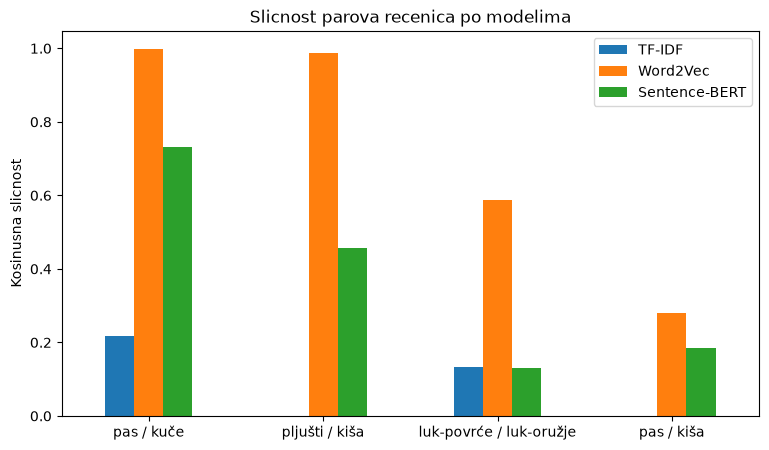

In [18]:
poredjenje.plot(kind='bar', figsize=(9, 5))
plt.ylabel('Kosinusna slicnost')
plt.xticks(rotation=0)
plt.title('Slicnost parova recenica po modelima')
plt.show()

Vektore možemo i nacrtati. Pošto imaju mnogo dimenzija, koristimo **PCA** da ih spustimo na 2 dimenzije. Rečenice istog značenja treba da budu blizu.

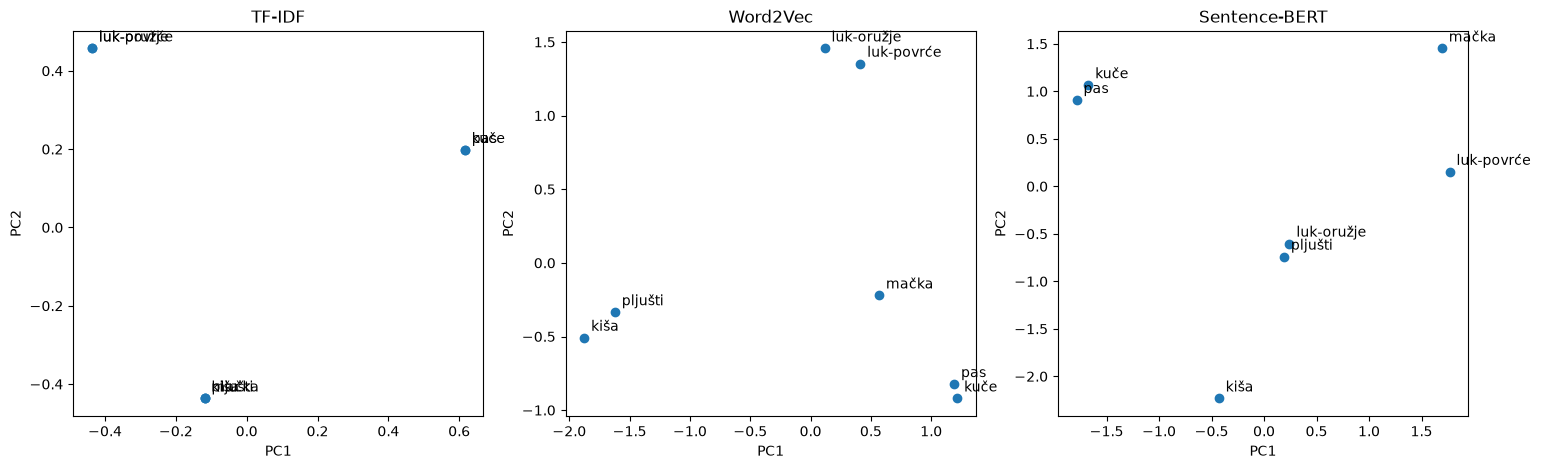

In [19]:
from sklearn.decomposition import PCA

modeli = {'TF-IDF': X_tfidf.toarray(), 'Word2Vec': X_w2v, 'Sentence-BERT': X_sbert}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (naziv, X) in zip(axes, modeli.items()):
    X_2d = PCA(n_components=2).fit_transform(X)
    ax.scatter(X_2d[:, 0], X_2d[:, 1])
    for i, oznaka in enumerate(oznake):
        ax.annotate(oznaka, (X_2d[i, 0], X_2d[i, 1]), textcoords='offset points', xytext=(5, 5))
    ax.set_title(naziv)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.show()

## Zaključak

| Model | Na osnovu čega pravi vektor | Zna da su „pas“ i „kuče“ slični? | Razlikuje „luk“ povrće od „luk“ oružja? | Dužina vektora |
|---|---|---|---|---|
| TF-IDF | brojanje reči i koliko su retke | NE | NE | broj reči u rečniku (retka matrica) |
| Word2Vec | kontekst - reči koje stoje okolo | Da | NE (jedna reč = jedan vektor) | po izboru, npr. 100-300 |
| Sentence-BERT | značenje cele rečenice (pažnja) | DA | DA | fiksna, npr. 384 ili 768 |

Kada šta koristiti:
- **TF-IDF** - brzo, bez treniranja i bez interneta; dobar za duže tekstove gde su važne ključne reči.
- **Word2Vec** - kada imamo svoj veliki korpus iz neke oblasti i želimo vektore reči.
- **Sentence-BERT** - kada je važno značenje (pretraga po smislu, pronalaženje parafraza, klasterovanje kratkih tekstova); sporiji je i zahteva veći model.